# pso_battery_optimizer.ipynb  (Sarvesh)
PSO-optimised 96-step battery schedule.

**Method:** a particle = 96 battery power set-points (MW). A full AC power flow on 10,458 buses is too slow inside a PSO loop, so PSO scores particles with a *surrogate* (cost, peak, losses, Vmin) **calibrated from real pandapower runs**. The final schedule is then **validated with full AC power flow** for all 96 steps.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")                       # folder containing sarvesh_lib.py
import simbench as sb, pandapower as pp
from sarvesh_lib import *

net = sb.get_simbench_net("1-MVLV-urban-all-0-sw")
profiles = sb.get_absolute_values(net, profiles_instead_of_study_cases=True)
print(len(net.bus), "buses |", len(net.storage), "storage units (should be 0 before we add ours)")

10458 buses | 0 storage units (should be 0 before we add ours)


In [2]:
import json
d = json.load(open("output/battery_config.json"))
cfg = BatteryConfig(**d)
sidx = add_battery(net, cfg)

DAY_INDEX = 343                         # 09-12-2016 (annual peak day, 0-based day of year)
DAY_START = DAY_INDEX * 96

## 1. Price signal (96 steps)
Use Sujit's hybrid forecast. Put his 96-step forecast in `output/price_forecast_day.csv` with a column `price_forecast`. If it is missing a synthetic shape is used so you can test.

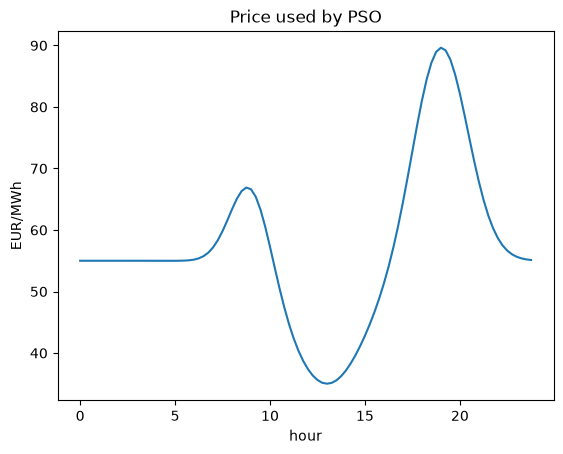

In [3]:
import os
if os.path.exists("output/price_forecast_day.csv"):
    price = pd.read_csv("output/price_forecast_day.csv")["price_forecast"].values[:T]
    assert len(price) == T, "need 96 price values"
else:
    h = np.arange(T)/4
    price = 55 + 35*np.exp(-((h-19)/2)**2) + 15*np.exp(-((h-9)/1.5)**2) - 20*np.exp(-((h-13)/3)**2)
    print("WARNING: synthetic price used")
plt.plot(np.arange(T)/4, price); plt.xlabel("hour"); plt.ylabel("EUR/MWh"); plt.title("Price used by PSO"); plt.show()

## 2. Calibrate surrogate from real AC power flows (~1-2 min per 100 power flows)

In [4]:
sur = calibrate_surrogate_from_pf(net, profiles, DAY_START, sidx, cfg, price, sample_every=4)
print("loss  poly (a,b,c):", sur.loss_coef)
print("Vmin  poly (d,e)  :", sur.vmin_coef)
print("base import: min %.1f  max %.1f MW" % (sur.base_import_mw.min(), sur.base_import_mw.max()))

loss  poly (a,b,c): [1.79311772e-05 3.88438899e-03 2.74566026e-01]
Vmin  poly (d,e)  : [-8.09412599e-04  1.01486815e+00]
base import: min 3.1  max 19.4 MW


## 3. Run PSO

iter   0  best fitness = 1.89043
iter  25  best fitness = 1.78681
iter  50  best fitness = 1.76953
iter  75  best fitness = 1.76100
iter 100  best fitness = 1.75572
iter 125  best fitness = 1.75118
iter 150  best fitness = 1.74762
iter 175  best fitness = 1.74532
iter 199  best fitness = 1.74440


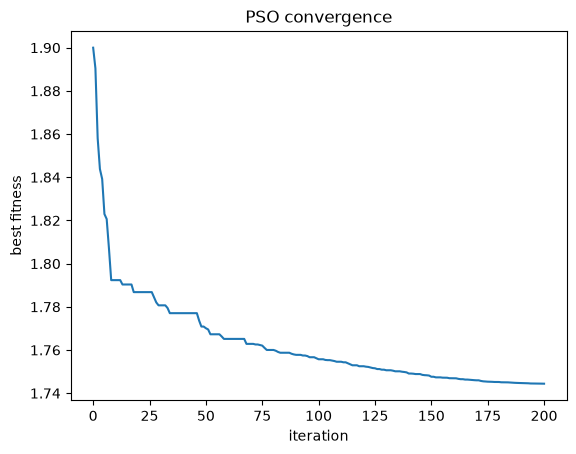

In [5]:
# Weights: tune these and justify in the viva.  cost / peak / losses are normalised to the no-battery case.
WEIGHTS = dict(cost=1.0, peak=0.6, loss=0.3, volt=50.0, soc_end=2.0, wear=0.02)

fitness = make_fitness(sur, cfg, WEIGHTS)
seed_rule = rule_based_schedule(price, cfg)
best, best_f, hist = pso(fitness, dim=T, lb=-cfg.p_max_mw, ub=cfg.p_max_mw,
                         init_particles=[np.zeros(T), seed_rule],
                         n_particles=80, iters=200, seed=42)
p_pso, E_pso = simulate_schedule(best, cfg)
plt.plot(hist); plt.xlabel("iteration"); plt.ylabel("best fitness"); plt.title("PSO convergence"); plt.show()

## 4. Compare: no battery / simple rule / PSO  (surrogate view)

In [6]:
strategies = {"No battery": np.zeros(T), "Simple rule": seed_rule, "PSO": best}
sched, rows = {}, []
for name, s in strategies.items():
    p, E = simulate_schedule(s, cfg)
    m = evaluate(p, sur, cfg, E)
    sched[name] = (p[0], E[0])
    rows.append(dict(strategy=name, cost_EUR=m["cost"][0], peak_MW=m["peak"][0],
                     losses_MWh=m["loss_mwh"][0], vmin_pu=m["vmin_min"][0],
                     end_SOC_pct=E[0,-1]/cfg.e_cap_mwh*100, equiv_cycles=m["throughput"][0]/2))
cmp_sur = pd.DataFrame(rows).set_index("strategy"); display(cmp_sur.round(3))

,cost_EUR,peak_MW,losses_MWh,vmin_pu,end_SOC_pct,equiv_cycles
strategy,,,,,,
No battery,12875.096,19.359,7.479,0.999,50.000,0.000
Simple rule,11872.536,18.264,7.456,1.000,10.000,1.183
PSO,12551.407,14.359,7.481,1.003,47.217,0.572


## 5. Full AC power-flow validation of the 3 schedules (96 power flows each)

In [7]:
val = {}
for name, (p, E) in sched.items():
    val[name] = run_day(net, profiles, DAY_START, p_batt=p, sidx=sidx)
    print(name, "done | non-converged steps:", int((~val[name].converged).sum()))
set_battery_power(net, sidx, 0.0)

def summ(df, price):
    dt = DT_H
    return dict(cost_EUR=(df.grid_import_mw*price*dt).sum(), peak_import_MW=df.grid_import_mw.max(),
                min_voltage_pu=df.v_min_pu.min(), max_line_loading_pct=df.max_line_loading_pct.max(),
                max_trafo_loading_pct=df.max_trafo_loading_pct.max(),
                losses_MWh=((df.line_losses_mw+df.transformer_losses_mw)*dt).sum(),
                violation_steps=int((df.voltage_violation_count>0).sum()+(df.overload_count>0).sum()))
final = pd.DataFrame({k: summ(v, price) for k, v in val.items()}).T
display(final.round(4))
final.to_csv("output/battery_impact_comparison.csv")

No battery done | non-converged steps: 0
Simple rule done | non-converged steps: 0
PSO done | non-converged steps: 0


,cost_EUR,peak_import_MW,min_voltage_pu,max_line_loading_pct,max_trafo_loading_pct,losses_MWh,violation_steps
No battery,12875.0956,19.3592,0.9879,36.7454,31.3781,7.5154,0.0
Simple rule,11872.5504,18.2679,0.9879,36.7454,31.3781,7.5213,0.0
PSO,12551.3233,14.3585,0.9879,36.7454,31.3781,7.5170,0.0


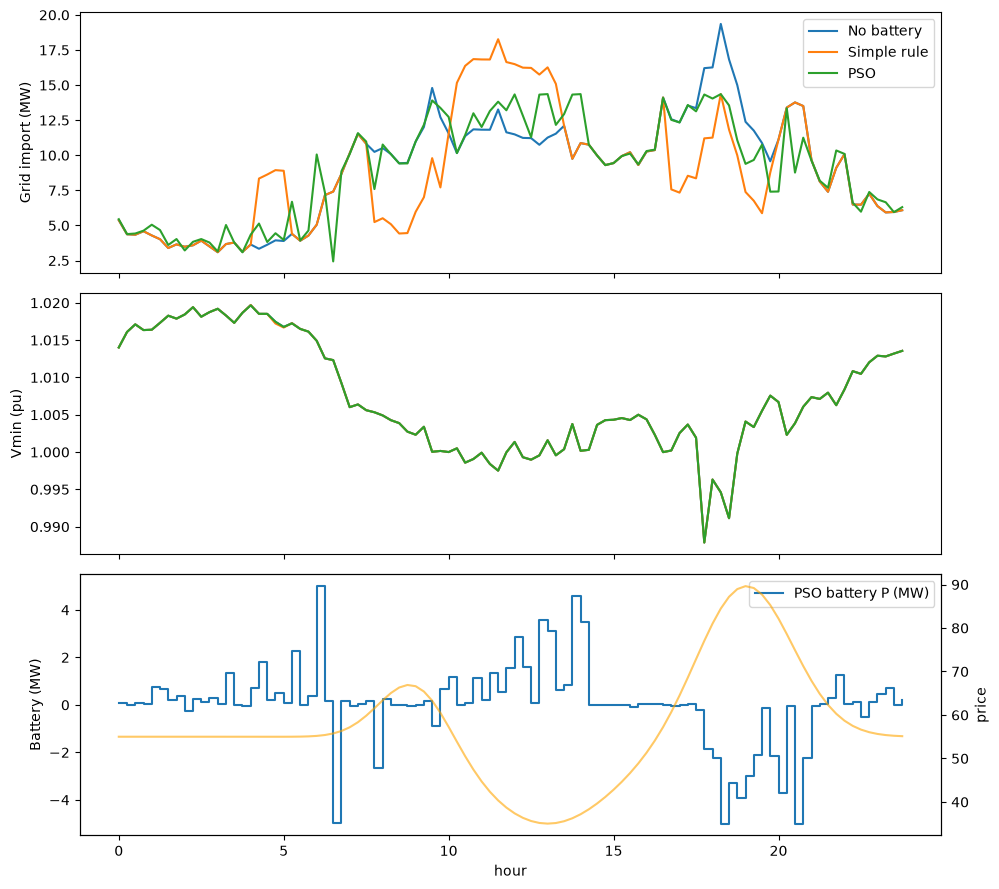

In [8]:
fig, ax = plt.subplots(3,1, figsize=(10,9), sharex=True)
h = np.arange(T)/4
for name, df in val.items():
    ax[0].plot(h, df.grid_import_mw, label=name)
    ax[1].plot(h, df.v_min_pu, label=name)
ax[0].set_ylabel("Grid import (MW)"); ax[0].legend(); ax[1].set_ylabel("Vmin (pu)")
ax[2].step(h, sched["PSO"][0], where="post", label="PSO battery P (MW)")
ax2 = ax[2].twinx(); ax2.plot(h, price, c="orange", alpha=.6); ax2.set_ylabel("price")
ax[2].set_ylabel("Battery (MW)"); ax[2].set_xlabel("hour"); ax[2].legend(); plt.tight_layout(); plt.show()

## 6. Export for the team

In [10]:
out = schedule_to_dataframe(
    p_pso[0], E_pso[0], price, cfg,  # Select the single schedule's 1-D energy history
    start_ts="2016-12-09"
)

out.to_csv("output/battery_schedule_pso_96.csv", index=False)
val["PSO"].to_csv(
    "output/battery_pso_powerflow_validation.csv",
    index=False
)

print(out.head(8))

   step           timestamp      price  battery_power_mw  battery_soc  \
0     0 2016-12-09 00:00:00  55.000000          0.069925    50.083036   
1     1 2016-12-09 00:15:00  55.000000          0.013462    50.099021   
2     2 2016-12-09 00:30:00  54.999999          0.087299    50.202688   
3     3 2016-12-09 00:45:00  54.999999          0.039281    50.249335   
4     4 2016-12-09 01:00:00  54.999998          0.763637    51.156153   
5     5 2016-12-09 01:15:00  54.999996          0.652665    51.931193   
6     6 2016-12-09 01:30:00  54.999992          0.217226    52.189149   
7     7 2016-12-09 01:45:00  54.999984          0.379222    52.639475   

  battery_mode  
0       CHARGE  
1       CHARGE  
2       CHARGE  
3       CHARGE  
4       CHARGE  
5       CHARGE  
6       CHARGE  
7       CHARGE  
